# The EM Algorithm for Gaussian Mixtures

**Course:** Machine Learning (20.IDI12) · **Mentor:** Prof. Branimir Todorović · **Author:** Elvir Muslić

The code half of the seminar paper: scikit-learn's `GaussianMixture` runs EM, one iteration computed by hand with NumPy and SciPy checks it, and the notebook computes every number, table and figure of Sections 3.4 and 5. Run it from this folder with `.venv/bin/jupyter nbconvert --to notebook --execute --inplace em_project.ipynb`.

## Part 0. Setup
The imports, the plot style (8 pt text, figures as wide as the paper's text, one color and one line style per component) and two helpers: `weighted_densities`, the terms $\pi_k \mathcal{N}(x_i \mid \mu_k, \Sigma_k)$ of the mixture (2.1), and `log_likelihood`, the log-likelihood (2.2). The last line prints the versions.

In [1]:
import logging
import platform
import time
import warnings
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import scipy
import sklearn
from matplotlib.patches import Ellipse
from scipy.stats import multivariate_normal
from sklearn.exceptions import ConvergenceWarning
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler

%config InlineBackend.figure_format = "retina"

START = time.perf_counter()
# below, fit() is asked for one iteration at a time on purpose, so its warning is expected
warnings.filterwarnings("ignore", category=ConvergenceWarning)
Path("figures").mkdir(exist_ok=True)
# fontTools would warn about the old timestamps of the Computer Modern fonts that the PDFs embed
logging.getLogger("fontTools").setLevel(logging.ERROR)
TEXTWIDTH = 360 / 72.27                                         # the paper's text width in inches
plt.rcParams.update({
    "font.size": 8, "axes.titlesize": 8, "axes.labelsize": 8, "figure.labelsize": 8,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "mathtext.fontset": "cm", "lines.linewidth": 1.0,
    "axes.grid": True, "grid.linestyle": ":", "grid.alpha": 0.6, "pdf.fonttype": 42,
    "figure.constrained_layout.use": True})
COLOR = np.array([[0.05, 0.25, 0.55], [0.95, 0.55, 0.10]])     # components 1 and 2: blue, orange
LINE = ("-", "--")                                              # solid and dashed, for grayscale


def weighted_densities(X, weights, means, covs):
    """pi_k N(x_i | mu_k, Sigma_k), the terms of the mixture (2.1): one row per point i,
    one column per component k."""
    return np.column_stack([w * multivariate_normal.pdf(X, m, S)
                            for w, m, S in zip(weights, means, covs)])


def log_likelihood(X, weights, means, covs):
    """The log-likelihood (2.2): the sum over the points of log p(x_i)."""
    return np.log(weighted_densities(X, weights, means, covs).sum(axis=1)).sum()


print(f"Python {platform.python_version()}, NumPy {np.__version__}, SciPy {scipy.__version__}, "
      f"scikit-learn {sklearn.__version__}, Matplotlib {matplotlib.__version__}")

Python 3.14.7, NumPy 2.5.3, SciPy 1.18.1, scikit-learn 1.9.1, Matplotlib 3.11.2


## Part 1. One iteration by hand (Section 3.4)
Four points on a line, $x = (1, 2, 6, 7)$, two components, and the start $\pi = (\tfrac12, \tfrac12)$, $\mu = (0, 5)$, $\sigma^2 = (1, 1)$.
- **E-step (3.1):** the responsibilities of a point are its weighted densities divided by their sum, so they add up to 1.
- **M-step (3.2):** $N_k$ is the sum of the responsibilities of component $k$; the new weight is $N_k / n$, the new mean is the responsibility-weighted average of the points, and the new variance the responsibility-weighted average of their squared distances from the new mean.

The printed values are Table 1 of the paper; the log-likelihood rises, consistent with Theorem 4.1.

In [2]:
x = np.array([[1.0], [2.0], [6.0], [7.0]])                     # one point per row
weights, means, covs = np.array([0.5, 0.5]), np.array([[0.0], [5.0]]), np.array([[[1.0]], [[1.0]]])

dens = weighted_densities(x, weights, means, covs)
resp = dens / dens.sum(axis=1, keepdims=True)                  # E-step (3.1), a row per point
N_k = resp.sum(axis=0)                                         # M-step (3.2)
new_weights = N_k / len(x)
new_means = resp.T @ x / N_k[:, None]
new_vars = (resp * (x - new_means.T) ** 2).sum(axis=0) / N_k

lines = [f"{'':17s} {'k = 1':>7s} {'k = 2':>7s}"]
for i, (xi, (g1, g2)) in enumerate(zip(x[:, 0], resp), start=1):
    lines.append(f"{f'gamma_{i}k, x_{i} = {xi:.0f}':17s} {g1:7.4f} {g2:7.4f}")
for name, values in (("N_k", N_k), ("pi_k", new_weights), ("mu_k", new_means[:, 0]),
                     ("sigma^2_k", new_vars)):
    lines.append(f"{name:17s} {values[0]:7.4f} {values[1]:7.4f}")
lines.append(f"log-likelihood: {log_likelihood(x, weights, means, covs):.4f} before the step, "
             f"{log_likelihood(x, new_weights, new_means, new_vars[:, None, None]):.4f} after")
print("\n".join(lines))

                    k = 1   k = 2
gamma_1k, x_1 = 1  0.9994  0.0006
gamma_2k, x_2 = 2  0.9241  0.0759
gamma_3k, x_3 = 6  0.0000  1.0000
gamma_4k, x_4 = 7  0.0000  1.0000
N_k                1.9236  2.0764
pi_k               0.4809  0.5191
mu_k               1.4804  6.3341
sigma^2_k          0.2496  0.9611
log-likelihood: -11.3689 before the step, -6.3155 after


## Part 2. Experiments (Section 5)
scikit-learn's `GaussianMixture` is the method, with full covariances and `reg_covar=0`; the hand iteration is the check.

### The hand iteration against scikit-learn (Section 5.1)
`GaussianMixture` starts from the given weights, means and precisions (inverse covariances). With `max_iter=1`, `fit()` runs one E-step and one M-step, and `reg_covar=0` turns off the small number that it would otherwise add to every variance. Its parameters and its log-likelihood must equal the hand values to machine precision; the one difference in the M-step is the ten machine epsilons that scikit-learn adds to every $N_k$ against a division by zero.

In [3]:
gm = GaussianMixture(2, weights_init=weights, means_init=means, precisions_init=np.linalg.inv(covs),
                     reg_covar=0, max_iter=1).fit(x)
difference = max(abs(gm.weights_ - new_weights).max(), abs(gm.means_[:, 0] - new_means[:, 0]).max(),
                 abs(gm.covariances_.ravel() - new_vars).max())
print("\n".join([
    "scikit-learn, one call of fit() from the same start, with max_iter=1 and reg_covar=0:",
    f"  pi = {gm.weights_.round(4)}, mu = {gm.means_[:, 0].round(4)}, "
    f"sigma^2 = {gm.covariances_.ravel().round(4)}",
    f"  largest difference from the hand values: {difference:.1e}",
    f"  log-likelihood after the step: {gm.score(x) * len(x):.4f}"]))

scikit-learn, one call of fit() from the same start, with max_iter=1 and reg_covar=0:
  pi = [0.4809 0.5191], mu = [1.4804 6.3341], sigma^2 = [0.2496 0.9611]
  largest difference from the hand values: 6.2e-15
  log-likelihood after the step: -6.3155


### Algorithm 1 with scikit-learn (Section 3.3)
`run_em` runs Algorithm 1 from a given start. It keeps one `GaussianMixture` with `warm_start=True` and `max_iter=1`, so every call of `fit()` continues from the current parameters and performs one E-step and one M-step. After each call it records the log-likelihood, $n$ times `score()` (the mean per point), and it stops when the log-likelihood changes by less than $10^{-10}$, or after 1000 iterations. It returns the model, the log-likelihoods and the parameters after every iteration.

In [4]:
def run_em(X, weights, means, covs, tol=1e-10, max_iter=1000):
    """Algorithm 1 with scikit-learn, one iteration per call of fit(); returns the model,
    the log-likelihoods and the parameters after every iteration."""
    gm = GaussianMixture(len(weights), weights_init=weights, means_init=means,
                         precisions_init=np.linalg.inv(covs), reg_covar=0, max_iter=1,
                         warm_start=True)
    logliks, states = [log_likelihood(X, weights, means, covs)], [(weights, means, covs)]
    for _ in range(max_iter):
        gm.fit(X)                                                   # one E-step and one M-step
        logliks.append(gm.score(X) * len(X))                        # score() is the mean per point
        states.append((gm.weights_, gm.means_, gm.covariances_))
        if abs(logliks[-1] - logliks[-2]) < tol:                    # the stopping test
            break
    return gm, np.array(logliks), states

### Old Faithful: Table 2, Figures 1 and 2 (Section 5.2)
The 272 eruptions of the data set `faithful` (eruption time and waiting time to the next eruption, in minutes) are standardized: each column is centered at its mean and divided by its standard deviation. EM starts from a deliberately poor guess: equal weights, the means $(-1.5, 1.5)$ and $(1.5, -1.5)$, where there are no points, and identity covariances. Every log-likelihood below is that of the standardized data; the table converts the fit back to minutes.

In [5]:
X_min = np.loadtxt("data/faithful.csv", delimiter=",", skiprows=1)   # eruption, waiting (min)
scaler = StandardScaler()
X = scaler.fit_transform(X_min)                     # standardized: mean 0, standard deviation 1
start = (np.array([0.5, 0.5]), np.array([[-1.5, 1.5], [1.5, -1.5]]),     # weights, means
         np.array([np.eye(2), np.eye(2)]))                                 # covariances

gm, ll, states = run_em(X, *start)
# the first iteration past half of the climb from t = 1, and the smallest rise of ll before it
t_half = np.argmax(ll >= (ll[1] + ll[-1]) / 2)
plateau = np.diff(ll)[1:t_half].min()
means_min = scaler.inverse_transform(gm.means_)                     # back to minutes
covs_min = gm.covariances_ * np.outer(scaler.scale_, scaler.scale_)
lines = [f"Old Faithful: {len(X)} eruptions, {X.shape[1]} variables, standardized",
         f"EM from the poor start: {len(ll) - 1} iterations, final log-likelihood {ll[-1]:.4f}",
         f"log-likelihood {ll[0]:.2f} at the start and {ll[1]:.2f} after one iteration",
         f"half of the climb from t = 1 reached at iteration {t_half}; "
         f"smallest rise between t = 1 and {t_half}: {plateau:.3f}",
         f"smallest change over all iterations: {np.diff(ll).min():.1e}",
         "",
         f"{'':16s} {'mean (min)':^14s}  {'covariance (min^2)':^26s}",
         f"{'component':9s} {'weight':>6s} {'erupt.':>6s} {'wait.':>7s}  "
         f"{'var e':>8s} {'cov ew':>8s} {'var w':>8s}"]
for k in range(2):
    lines.append(f"{k + 1:9d} {gm.weights_[k]:6.3f} {means_min[k][0]:6.2f} {means_min[k][1]:7.2f}  "
                 f"{covs_min[k][0, 0]:8.3f} {covs_min[k][0, 1]:8.3f} {covs_min[k][1, 1]:8.3f}")
print("\n".join(lines))

Old Faithful: 272 eruptions, 2 variables, standardized
EM from the poor start: 53 iterations, final log-likelihood -385.4607
log-likelihood -1331.48 at the start and -542.98 after one iteration
half of the climb from t = 1 reached at iteration 35; smallest rise between t = 1 and 35: 0.035
smallest change over all iterations: 2.2e-11

                   mean (min)        covariance (min^2)    
component weight erupt.   wait.     var e   cov ew    var w
        1  0.356   2.04   54.48     0.069    0.435   33.697
        2  0.644   4.29   79.97     0.170    0.941   36.046


In Figure 1, the points are colored by their responsibilities (dark blue for the first component, orange for the second, a mix when shared); each component has its ellipse two standard deviations around its mean (solid for the first, dashed for the second) and its mean marked, $+$ for the first and $\times$ for the second. The panels show the start, the first iteration, iteration `t_half`, when the log-likelihood has covered half of its climb from $t = 1$, and the last iteration. Figure 2 shows (a) the log-likelihood for $t \ge 1$, leaving out the start, $t = 0$, for scale, and (b) the gain of every iteration on a log scale, with the tolerance $10^{-10}$ of the stopping test dashed.

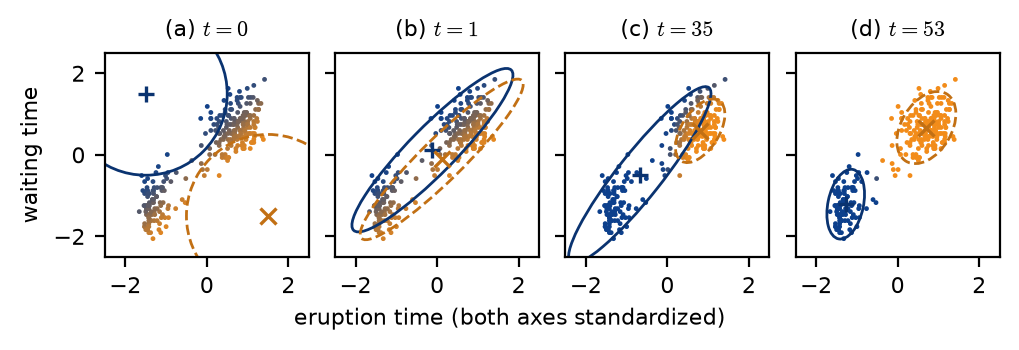

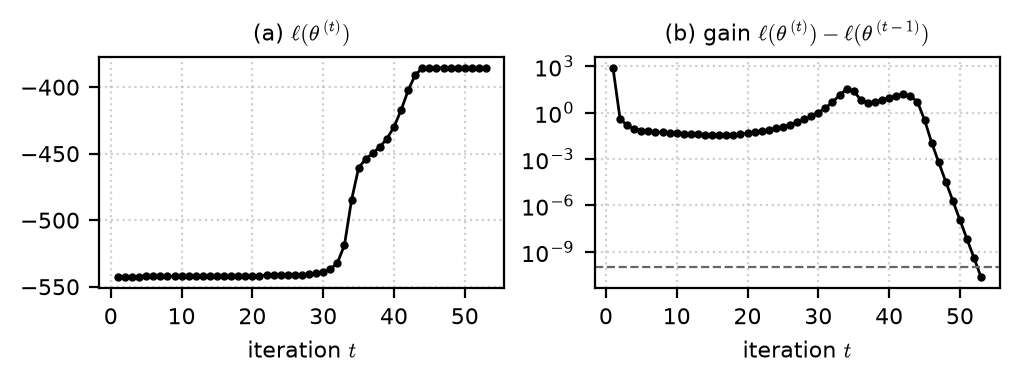

In [6]:
def draw_state(ax, weights, means, covs, title):
    """The points colored by their responsibilities, and the 2-sigma ellipse and the mean
    of each component."""
    dens = weighted_densities(X, weights, means, covs)
    resp = dens / dens.sum(axis=1, keepdims=True)
    # the color of point i is gamma_i1 * COLOR[0] + gamma_i2 * COLOR[1]
    ax.scatter(X[:, 0], X[:, 1], c=resp @ COLOR, s=3, linewidths=0)
    for k in range(2):
        vals, vecs = np.linalg.eigh(covs[k])                        # axes; eigenvalues ascending
        angle = np.degrees(np.arctan2(vecs[1, 1], vecs[0, 1]))
        ax.add_patch(Ellipse(means[k], 4 * np.sqrt(vals[1]), 4 * np.sqrt(vals[0]), angle=angle,
                             fill=False, color=0.8 * COLOR[k], ls=LINE[k]))
        ax.plot(*means[k], marker="+x"[k], ms=6, mew=1.2, color=0.8 * COLOR[k], ls="none")
    ax.set(title=title, xlim=(-2.5, 2.5), ylim=(-2.5, 2.5), xticks=(-2, 0, 2), yticks=(-2, 0, 2),
           aspect="equal")
    ax.grid(False)


fig, axes = plt.subplots(1, 4, figsize=(TEXTWIDTH, 1.6), sharex=True, sharey=True)
for ax, t, tag in zip(axes, (0, 1, t_half, len(ll) - 1), "abcd"):
    draw_state(ax, *states[t], f"({tag}) $t = {t}$")
axes[0].set_ylabel("waiting time")
fig.supxlabel("eruption time (both axes standardized)")
fig.savefig("figures/em_iterations.pdf")

# in black, since dark blue means the first component
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(TEXTWIDTH, 1.8))
t = np.arange(1, len(ll))                                           # the iterations 1, 2, ...
ax1.plot(t, ll[1:], "o-", color="k", ms=2)
ax1.set(title=r"(a) $\ell(\theta^{(t)})$", xlabel="iteration $t$")
ax2.semilogy(t, np.diff(ll), "o-", color="k", ms=2)
ax2.axhline(1e-10, color="0.4", ls="--", lw=0.8)                    # the tolerance of run_em
ax2.set(title=r"(b) gain $\ell(\theta^{(t)}) - \ell(\theta^{(t-1)})$", xlabel="iteration $t$")
fig.savefig("figures/em_loglik.pdf")
plt.show()

### Twenty random starts (Section 5.3)
Theorem 4.1 promises only that EM climbs; where it stops depends on the start. Twenty more runs start with the means at two randomly chosen data points, identity covariances and equal weights. A component that shrank onto a single point would let the log-likelihood grow without bound (Section 2.3), so the cell also prints the smallest covariance eigenvalue, the smallest variance of a component in any direction, over all 21 final fits: the poor start's and these twenty. The last line prints the run time of the whole notebook.

In [7]:
rng = np.random.default_rng(0)
runs = [run_em(X, np.array([0.5, 0.5]), X[rng.choice(len(X), size=2, replace=False)],
               np.array([np.eye(2), np.eye(2)])) for _ in range(20)]
finals = [r[1][-1] for r in runs]
iterations = [len(r[1]) - 1 for r in runs]
print(f"{len(runs)} random starts: final log-likelihoods {np.unique(np.round(finals, 4))}, "
      f"{min(iterations)} to {max(iterations)} iterations")
final_fits = [gm] + [r[0] for r in runs]                    # the poor start's and the twenty
smallest = min(np.linalg.eigvalsh(model.covariances_).min() for model in final_fits)
print(f"smallest covariance eigenvalue over all {len(final_fits)} final fits: {smallest:.3f} "
      "(standardized units)")
print(f"\nrun time of the whole notebook: {time.perf_counter() - START:.0f} s")

20 random starts: final log-likelihoods [-385.4607], 11 to 37 iterations
smallest covariance eigenvalue over all 21 final fits: 0.047 (standardized units)

run time of the whole notebook: 1 s
